# پروژه جامع پاک‌سازی و تحلیل اکتشافی داده‌های قیمت مسکن (Ames Housing Dataset)

در این نوت‌بوک، تمامی مراحل **پاک‌سازی داده‌ها (Data Cleaning)**، **تحلیل اکتشافی (EDA)** و **آماده‌سازی ویژگی‌ها (Feature Preprocessing)** بر روی مجموعه داده `train_3_61FH.csv` به صورت گام‌به‌گام پیاده‌سازی و تشریح شده است.

### سرفصل‌های اصلی این نوت‌بوک:
1. بارگذاری کتابخانه‌ها و بررسی اولیه ساختار داده‌ها
2. حذف ستون‌های غیرضروری یا دارای مقادیر گمشده بسیار زیاد (Deleting Columns)
3. مدیریت و پر کردن مقادیر گمشده (Handling Missing Values)
4. رسم نمودارهای متنوع تحلیلی و آماری صرفاً با استفاده از کتابخانه `matplotlib` (`plt`)
5. بررسی همبستگی ویژگی‌های عددی و دسته‌ای و تفسیر آماری آن‌ها (Correlation & Categorical Association)
6. نرمال‌سازی داده‌ها (Data Normalization & Scaling)
7. ذخیره‌سازی مجموعه داده نهایی و پاک‌سازی شده در قالب فایل CSV

## ۱. فراخوانی کتابخانه‌ها و بارگذاری داده‌ها

در این بخش، کتابخانه‌های استاندارد علم داده در پایتون را وارد می‌کنیم (بدون نیاز به نصب `seaborn` و صرفاً با استفاده از `matplotlib`):
- **`pandas` و `numpy`**: برای کار با جداول داده (DataFrame) و محاسبات ریاضی.
- **`matplotlib.pyplot` (`plt`)**: برای رسم تمامی نمودارهای آماری و ماتریس‌های حرارتی.
- **`scipy.stats`**: برای محاسبه آزمون‌های آماری مانند کای‌اسکوئر (Chi-Square) و برآورد چگالی (KDE) جهت سنجش ارتباط متغیرهای دسته‌ای و رسم منحنی توزیع.
- **`sklearn.preprocessing`**: برای نرمال‌سازی و استانداردسازی داده‌های عددی.

### پارامترهای مهم در `pd.read_csv()`:
- `filepath_or_buffer`: مسیر یا نام فایل CSV ورودی (`train_3_61FH.csv`).
- `keep_default_na=True`: به صورت پیش‌فرض رشته‌هایی مانند `NA`، `NaN` و `null` را به عنوان مقدار گمشده (`np.nan`) تشخیص می‌دهد.

In [1]:
# وارد کردن کتابخانه‌های مورد نیاز برای تحلیل و پاک‌سازی داده (فقط با استفاده از plt)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, gaussian_kde
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import warnings

# نادیده گرفتن هشدارهای غیرضروری برای خوانایی بهتر خروجی
warnings.filterwarnings('ignore')

# تنظیمات ظاهری نمودارها در matplotlib
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)

# بارگذاری فایل دیتاست
df = pd.read_csv('train.csv')

# نمایش ابعاد دیتاست (تعداد سطرها و ستون‌ها)
print(f"تعداد سطرها: {df.shape[0]} | تعداد ستون‌ها: {df.shape[1]}")

# نمایش ۵ سطر اول دیتاست
df.head()

تعداد سطرها: 1460 | تعداد ستون‌ها: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## ۲. بررسی اولیه ساختار و انواع داده‌ها

قبل از هرگونه تغییر، باید نوع داده‌های هر ستون (عددی یا متنی/دسته‌ای) و تعداد مقادیر غیرخالی (`Non-Null`) را بررسی کنیم.
- متد `df.info()` اطلاعات جامعی درباره نوع داده‌ها (`int64`, `float64`, `object`) و مصرف حافظه ارائه می‌دهد.
- متد `df.isnull().sum()` تعداد دقیق مقادیر گمشده را در هر ستون محاسبه می‌کند.

In [2]:
# محاسبه تعداد و درصد مقادیر گمشده در هر ستون
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

# ایجاد یک جدول خلاصه برای ستون‌های دارای داده گمشده
missing_df = pd.DataFrame({
    'تعداد مقادیر گمشده': missing_count,
    'درصد گمشده (%)': missing_percent
})
missing_df = missing_df[missing_df['تعداد مقادیر گمشده'] > 0].sort_values(by='درصد گمشده (%)', ascending=False)

print("ستون‌های دارای مقادیر گمشده:")
display(missing_df)

ستون‌های دارای مقادیر گمشده:


,تعداد مقادیر گمشده,درصد گمشده (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


## ۳. حذف ستون‌ها (Deleting Columns)

حذف ستون در پاک‌سازی داده به دو دلیل اصلی انجام می‌شود:
1. **ستون‌های شناسه‌گر (Identifier)**: مانند ستون `Id` که صرفاً شماره ردیف است و هیچ ارزش آماری یا پیش‌بینی‌کننده‌ای ندارد (حتی می‌تواند باعث بیش‌برازش یا Overfitting در مدل شود).
2. **ستون‌های با مقادیر گمشده بسیار بالا**: ستون‌هایی که بیش از ۸۰ درصد مقادیر آن‌ها گمشده است (مانند `PoolQC` با ۹۹.۵٪، `MiscFeature` با ۹۶.۳٪، `Alley` با ۹۳.۷٪ و `Fence` با ۸۰.۷٪) اطلاعات بسیار کمی دارند و نگه داشتن آن‌ها اغلب نویز ایجاد می‌کند.

### تشریح دقیق پارامترهای متد `df.drop()`:
- **`labels` یا `columns`**: نام ستون یا لیستی از نام ستون‌هایی که قصد حذف آن‌ها را داریم.
- **`axis`**: جهت حذف را مشخص می‌کند. مقدار `axis=1` (یا `'columns'`) به معنای حذف ستون و `axis=0` (یا `'index'`) به معنای حذف سطر است.
- **`inplace`**: اگر برابر با `True` باشد، تغییرات مستقیماً روی دیتافریم فعلی اعمال می‌شود و خروجی برنمی‌گرداند. اگر `False` باشد (حالت توصیه‌شده)، یک کپی جدید با تغییرات برمی‌گرداند.
- **`errors`**: مقدار پیش‌فرض `'raise'` است که در صورت نبودن نام ستون خطا می‌دهد؛ مقدار `'ignore'` در صورت نبودن ستون خطایی صادر نمی‌کند.

In [4]:
# لیست ستون‌هایی که باید حذف شوند (شناسه Id و ستون‌های با بیش از ۸۰٪ داده گمشده)
cols_to_drop = ['Id', 'PoolQC', 'MiscFeature', 'Alley', 'Fence']

# حذف ستون‌ها با استفاده از متد drop
df_cleaned = df.drop(columns=cols_to_drop, inplace=False, errors='ignore')

print(f"ستون‌های حذف شده: {cols_to_drop}")
print(f"ابعاد جدید دیتاست پس از حذف ستون‌ها: {df_cleaned.shape}")

ستون‌های حذف شده: ['Id', 'PoolQC', 'MiscFeature', 'Alley', 'Fence']
ابعاد جدید دیتاست پس از حذف ستون‌ها: (1460, 76)


## ۴. مدیریت و پر کردن مقادیر گمشده (Filling Missing Values)

در این دیتاست، برخی از مقادیر `NA` به معنای واقعی «داده ناموجود» نیستند، بلکه طبق مستندات دیتاست به معنای **«نداشتن آن امکانات»** هستند (مثلاً `NA` در `BsmtQual` یعنی خانه زیرزمین ندارد، یا در `GarageType` یعنی گاراژ ندارد). سایر مقادیر گمشده نیز باید با روش‌های آماری پر شوند.

### استراتژی پر کردن مقادیر گمشده در این بخش:
1. **متغیرهای دسته‌ای مرتبط با امکانات (زیرزمین، گاراژ، شومینه، نمای سنگی/آجری)**: با رشته `'None'` (به معنای نداشتن آن ویژگی) پر می‌شوند.
2. **متغیرهای عددی مرتبط با امکانات (مساحت گاراژ، سال ساخت گاراژ، مساحت نمای آجری)**: با عدد `0` پر می‌شوند.
3. **متغیر عددی `LotFrontage` (برِ زمین)**: چون این مقدار به محله (`Neighborhood`) بستگی دارد، بهترین روش پر کردن آن با **میانه (Median)** همان محله است تا تحت تأثیر داده‌های پرت قرار نگیرد.
4. **سایر متغیرهای دسته‌ای (مانند `Electrical`)**: با **مد (Mode - پرتکرارترین مقدار)** پر می‌شوند.

### تشریح دقیق پارامترهای متد `fillna()`:
- **`value`**: مقدار ثابت یا دیکشنری/سری مقادیری که باید جایگزین `NaN` شوند.
- **`method`**: روش پر کردن (مثلاً `'ffill'` برای پر کردن از مقدار قبلی یا `'bfill'` از مقدار بعدی - در داده‌های غیرسری زمانی کمتر استفاده می‌شود).
- **`inplace`**: اعمال تغییر درجا (`True`) یا بازگرداندن دیتافریم جدید (`False`).
- **`limit`**: حداکثر تعداد مقادیر متوالی `NaN` که باید پر شوند.

In [5]:
# ۱. پر کردن متغیرهای دسته‌ای که NA در آن‌ها به معنای 'نداشتن آن ویژگی' است با 'None'
none_cols = [
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType'
]
for col in none_cols:
    df_cleaned[col] = df_cleaned[col].fillna(value='None')

# ۲. پر کردن متغیرهای عددی مرتبط با گاراژ و نمای آجری با عدد 0
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'MasVnrArea']
for col in zero_cols:
    df_cleaned[col] = df_cleaned[col].fillna(value=0)

# ۳. پر کردن LotFrontage با میانه (Median) هر محله (Neighborhood)
df_cleaned['LotFrontage'] = df_cleaned.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

# ۴. پر کردن سایر ستون‌های باقی‌مانده (مانند Electrical) با مد (Mode)
for col in df_cleaned.columns:
    if df_cleaned[col].isnull().sum() > 0:
        mode_val = df_cleaned[col].mode()[0]
        df_cleaned[col] = df_cleaned[col].fillna(value=mode_val)

# بررسی نهایی برای اطمینان از صفر بودن تمام مقادیر گمشده
print(f"تعداد کل مقادیر گمشده باقی‌مانده در کل دیتاست: {df_cleaned.isnull().sum().sum()}")

تعداد کل مقادیر گمشده باقی‌مانده در کل دیتاست: 0


## ۵. تحلیل بصری و رسم نمودارهای متنوع (صرفاً با `matplotlib.pyplot`)

در این بخش، با رسم نمودارهای گوناگون توسط `plt`، توزیع متغیر هدف (`SalePrice`)، روابط بین ویژگی‌ها، داده‌های پرت (Outliers) و روندهای قیمتی را بررسی می‌کنیم:
1. **نمودار هیستوگرام و منحنی چگالی (`plt.hist` + `plt.plot`)**: برای بررسی چولگی (Skewness) قیمت فروش.
2. **نمودار جعبه‌ای (`plt.boxplot`)**: برای بررسی توزیع قیمت بر اساس کیفیت کلی ساخت (`OverallQual`) و شناسایی داده‌های پرت.
3. **نمودار پراکندگی همراه با خط برازش رگرسیون (`plt.scatter` + `np.polyfit`)**: برای مشاهده رابطه خطی بین متراژ زیربنا (`GrLivArea`) و قیمت فروش.
4. **نمودار میله‌ای (`plt.bar`)**: برای مقایسه میانگین قیمت خانه‌ها در محله‌های مختلف (`Neighborhood`).
5. **نمودار خطی (`plt.plot`)**: برای بررسی روند تغییر قیمت مسکن بر اساس سال ساخت (`YearBuilt`).

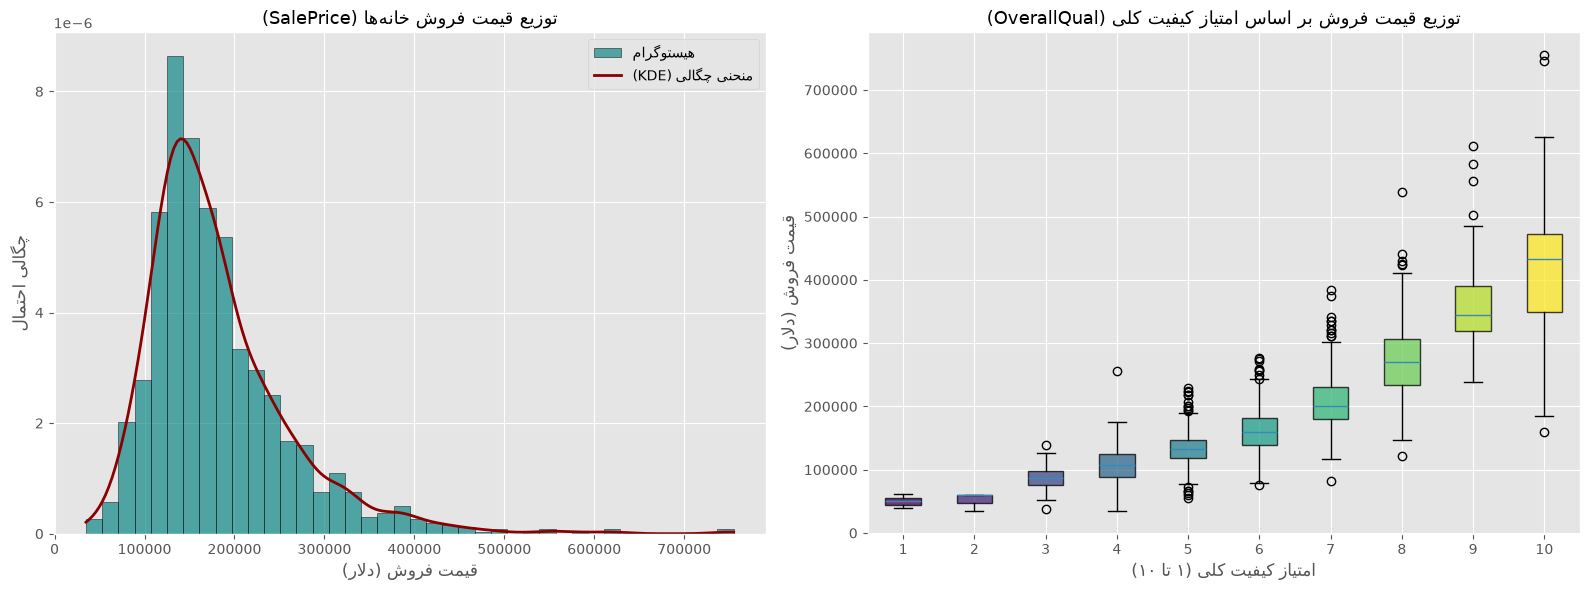

In [11]:
# ایجاد یک بوم با ۲ زیرنمودار در کنار هم با plt
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# نمودار ۱: هیستوگرام و منحنی چگالی قیمت فروش (SalePrice)
sale_prices = df_cleaned['SalePrice']
axes[0].hist(sale_prices, bins=40, density=True, color='teal', alpha=0.65, edgecolor='black', label='هیستوگرام')

# محاسبه و رسم منحنی چگالی (KDE) با scipy و plt.plot
kde = gaussian_kde(sale_prices)
x_vals = np.linspace(sale_prices.min(), sale_prices.max(), 200)
axes[0].plot(x_vals, kde(x_vals), color='darkred', linewidth=2, label='منحنی چگالی (KDE)')
axes[0].set_title('توزیع قیمت فروش خانه‌ها (SalePrice)', fontsize=13)
axes[0].set_xlabel('قیمت فروش (دلار)')
axes[0].set_ylabel('چگالی احتمال')
axes[0].legend()

# نمودار ۲: نمودار جعبه‌ای (Boxplot) قیمت فروش بر اساس کیفیت کلی ساخت (OverallQual)
qual_levels = sorted(df_cleaned['OverallQual'].unique())
box_data = [df_cleaned[df_cleaned['OverallQual'] == q]['SalePrice'].values for q in qual_levels]
bp = axes[1].boxplot(box_data, label=qual_levels, patch_artist=True)

# رنگ‌آمیزی جعبه‌های نمودار با پالت رنگی matplotlib
colors = plt.cm.viridis(np.linspace(0, 1, len(qual_levels)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

axes[1].set_title('توزیع قیمت فروش بر اساس امتیاز کیفیت کلی (OverallQual)', fontsize=13)
axes[1].set_xlabel('امتیاز کیفیت کلی (۱ تا ۱۰)')
axes[1].set_ylabel('قیمت فروش (دلار)')

plt.tight_layout()
plt.show()

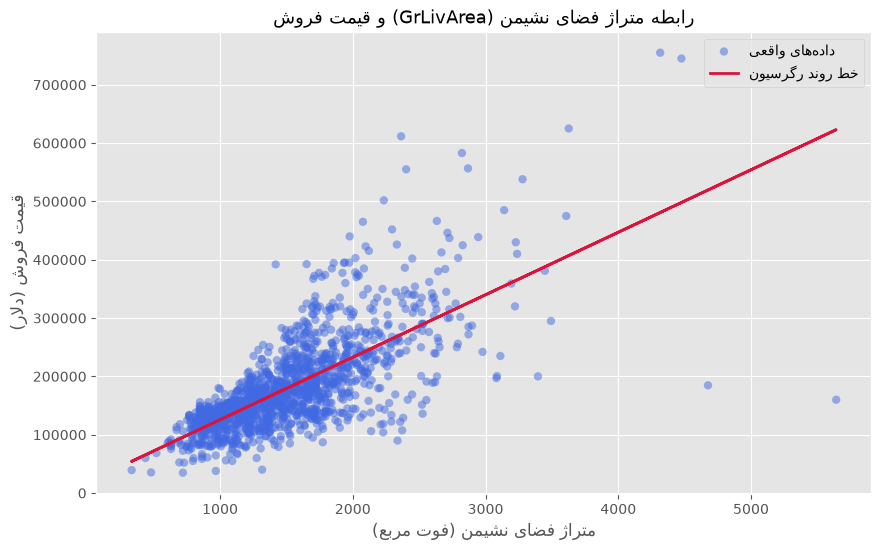

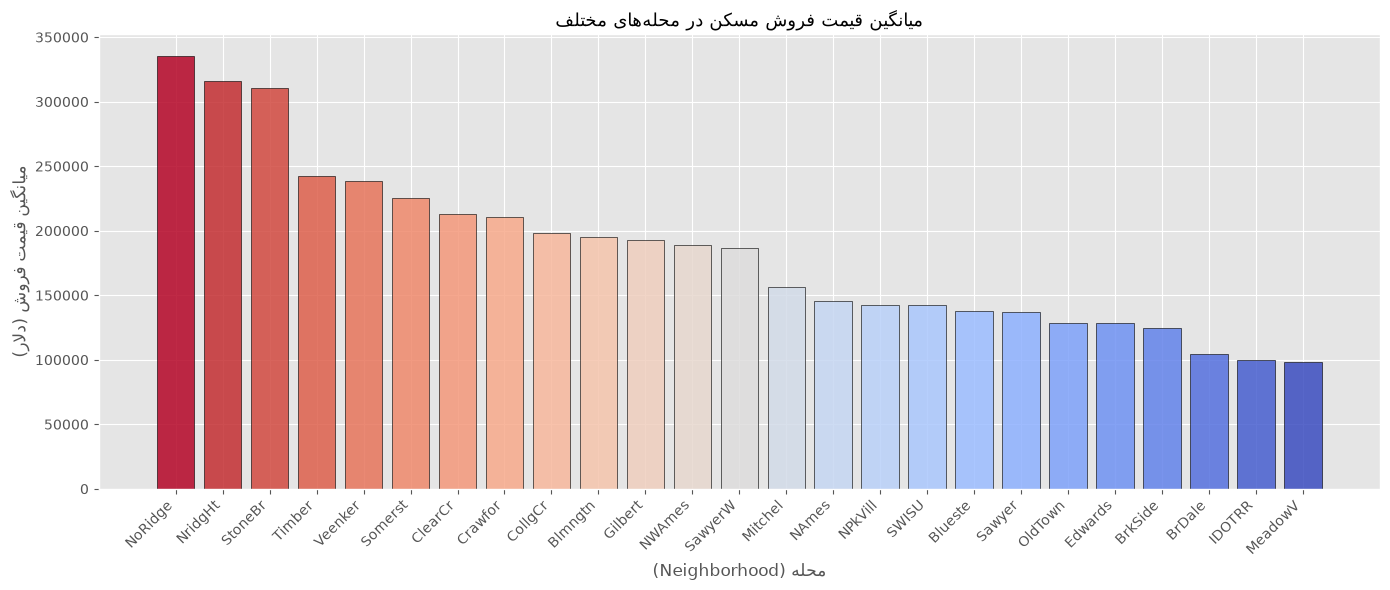

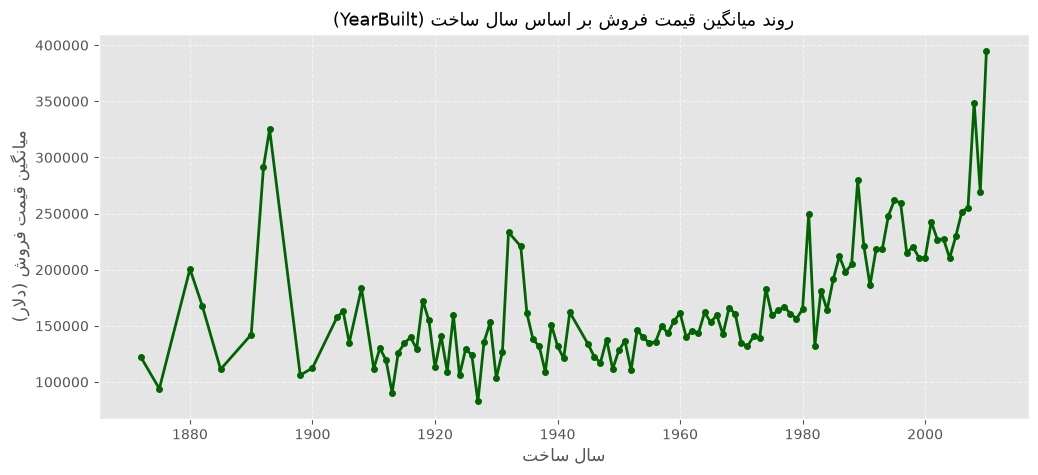

In [7]:
# نمودار ۳: نمودار پراکندگی متراژ فضای نشیمن (GrLivArea) در برابر قیمت فروش + خط رگرسیون
plt.figure(figsize=(10, 6))
x_area = df_cleaned['GrLivArea']
y_price = df_cleaned['SalePrice']
plt.scatter(x_area, y_price, alpha=0.5, color='royalblue', edgecolors='none', label='داده‌های واقعی')

# محاسبه شیب و عرض از مبدأ خط رگرسیون خطی با np.polyfit
m, b = np.polyfit(x_area, y_price, 1)
plt.plot(x_area, m * x_area + b, color='crimson', linewidth=2, label='خط روند رگرسیون')
plt.title('رابطه متراژ فضای نشیمن (GrLivArea) و قیمت فروش', fontsize=13)
plt.xlabel('متراژ فضای نشیمن (فوت مربع)')
plt.ylabel('قیمت فروش (دلار)')
plt.legend()
plt.show()

# نمودار ۴: میانگین قیمت فروش در محله‌های مختلف (مرتب شده از گران‌ترین به ارزان‌ترین)
plt.figure(figsize=(14, 6))
neigh_means = df_cleaned.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False)
bar_colors = plt.cm.coolwarm(np.linspace(1, 0, len(neigh_means)))
plt.bar(neigh_means.index, neigh_means.values, color=bar_colors, edgecolor='black', alpha=0.85)
plt.xticks(rotation=45, ha='right')
plt.title('میانگین قیمت فروش مسکن در محله‌های مختلف', fontsize=13)
plt.xlabel('محله (Neighborhood)')
plt.ylabel('میانگین قیمت فروش (دلار)')
plt.tight_layout()
plt.show()

# نمودار ۵: روند تغییر میانگین قیمت فروش بر اساس سال ساخت بنا
plt.figure(figsize=(12, 5))
year_means = df_cleaned.groupby('YearBuilt')['SalePrice'].mean()
plt.plot(year_means.index, year_means.values, color='darkgreen', linewidth=2, marker='o', markersize=4)
plt.title('روند میانگین قیمت فروش بر اساس سال ساخت (YearBuilt)', fontsize=13)
plt.xlabel('سال ساخت')
plt.ylabel('میانگین قیمت فروش (دلار)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## ۶. تحلیل همبستگی ویژگی‌های عددی و دسته‌ای و تفسیر آن

### الف) همبستگی ویژگی‌های عددی (Pearson Correlation)
ضریب همبستگی پیرسون عددی بین `-1` و `+1` است:
- نزدیک به `+1`: همبستگی مثبت قوی (با افزایش یک متغیر، دیگری نیز افزایش می‌یابد).
- نزدیک به `-1`: همبستگی منفی قوی (با افزایش یک متغیر، دیگری کاهش می‌یابد).
- نزدیک به `0`: عدم وجود رابطه خطی.

### ب) همبستگی و ارتباط بین ستون‌های دسته‌ای (Categorical Correlation - Cramér's V)
ضریب پیرسون برای داده‌های متنی/دسته‌ای (مانند `Neighborhood`, `KitchenQual`, `ExterQual`) کاربرد ندارد. برای سنجش میزان همبستگی بین دو متغیر دسته‌ای از معیار **Cramér's V** (مبتنی بر آزمون کای‌اسکوئر $\chi^2$) استفاده می‌کنیم.

#### تفسیر مقادیر Cramér's V (همبستگی دسته‌ای) به چه معناست؟
مقدار **Cramér's V** همواره عددی بین `0` تا `1` است:
- **`0.00` تا `0.10`**: ارتباط بسیار ضعیف یا عدم وابستگی (دو ستون تقریباً مستقل از هم هستند).
- **`0.10` تا `0.30`**: ارتباط ضعیف تا متوسط.
- **`0.30` تا `0.50`**: ارتباط متوسط تا قوی (دانستن مقدار یک ستون، اطلاعات خوبی درباره ستون دیگر می‌دهد).
- **بیشتر از `0.50`**: **همبستگی بسیار قوی / هم‌خطی دسته‌ای (Categorical Collinearity)**.

> **اهمیت عملی در مدل‌سازی:** اگر دو ستون دسته‌ای همبستگی بسیار بالایی (مثلاً بالای `0.7`) داشته باشند، به این معنی است که هر دو اطلاعات یکسانی را منتقل می‌کنند (مانند `Exterior1st` و `Exterior2nd` یا `GarageQual` و `GarageCond`) و می‌توان یکی از آن‌ها را برای کاهش پیچیدگی مدل حذف کرد.

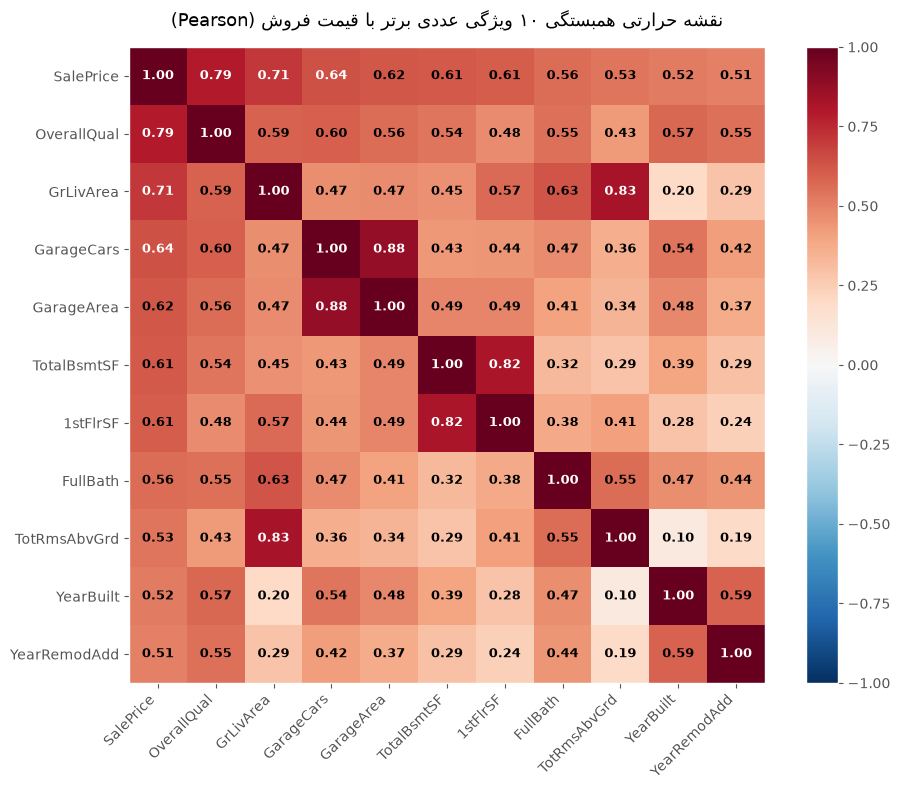

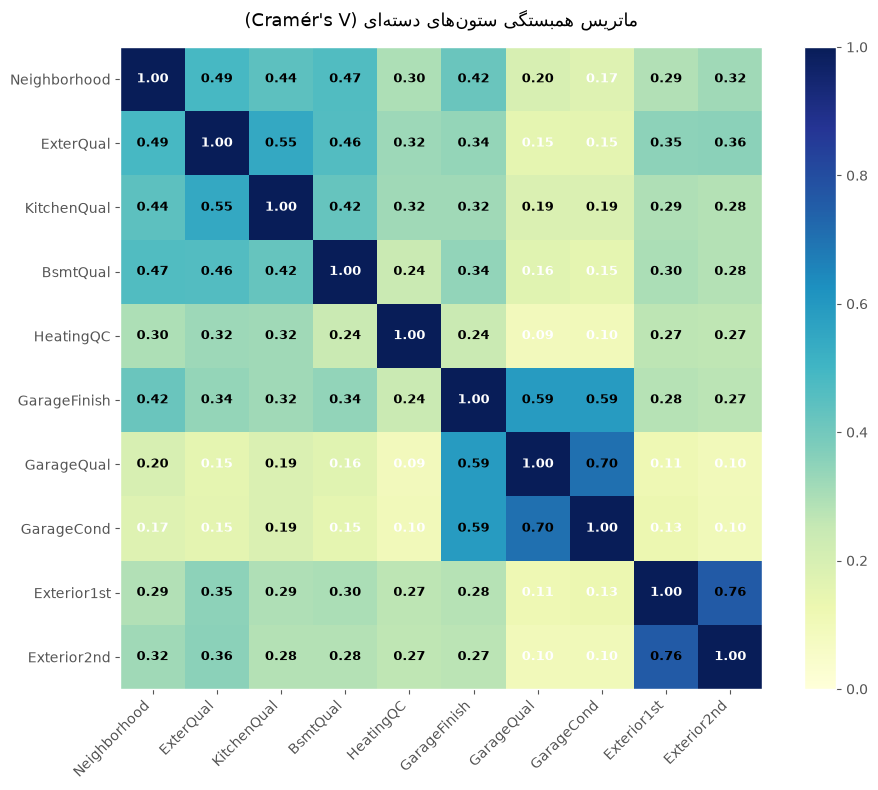

In [8]:
# تابع کمکی برای رسم نقشه حرارتی (Heatmap) با مقادیر عددی صرفاً با plt
def plot_heatmap_plt(matrix_df, title, cmap='RdBu_r', vmin=-1, vmax=1):
    fig, ax = plt.subplots(figsize=(11, 8))
    im = ax.imshow(matrix_df.values, cmap=cmap, vmin=vmin, vmax=vmax)
    
    # افزودن نوار راهنمای رنگ (Colorbar)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # تنظیم برچسب‌های محورهای X و Y
    cols = matrix_df.columns
    ax.set_xticks(np.arange(len(cols)))
    ax.set_yticks(np.arange(len(cols)))
    ax.set_xticklabels(cols, rotation=45, ha='right')
    ax.set_yticklabels(cols)
    ax.grid(False)
    
    # درج مقادیر عددی داخل هر سلول ماتریس
    for i in range(len(cols)):
        for j in range(len(cols)):
            val = matrix_df.iloc[i, j]
            text_color = 'white' if abs(val - (vmin + vmax)/2) > (vmax - vmin)*0.32 else 'black'
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=text_color, fontsize=9, fontweight='bold')
            
    ax.set_title(title, fontsize=13, pad=15)
    plt.tight_layout()
    plt.show()

# --- بخش الف: نقشه حرارتی همبستگی ویژگی‌های عددی با قیمت فروش ---
numeric_df = df_cleaned.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# انتخاب ۱۰ ویژگی عددی که بیشترین همبستگی را با SalePrice دارند
top_corr_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(11).index
top_corr_df = numeric_df[top_corr_features].corr()

plot_heatmap_plt(
    top_corr_df,
    title='نقشه حرارتی همبستگی ۱۰ ویژگی عددی برتر با قیمت فروش (Pearson)',
    cmap='RdBu_r', vmin=-1, vmax=1
)

# --- بخش ب: محاسبه ماتریس همبستگی برای ستون‌های دسته‌ای (Cramér's V) ---
def cramers_v(x, y):
    """محاسبه ضریب همبستگی Cramér's V بین دو ستون دسته‌ای"""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min((kcorr - 1), (rcorr - 1))
    return np.sqrt(phi2corr / denom) if denom > 0 else 0

# انتخاب چند ستون دسته‌ای مهم برای بررسی همبستگی متقابل
selected_cat_cols = [
    'Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual',
    'HeatingQC', 'GarageFinish', 'GarageQual', 'GarageCond', 'Exterior1st', 'Exterior2nd'
]

cramers_matrix = pd.DataFrame(index=selected_cat_cols, columns=selected_cat_cols, dtype=float)
for col1 in selected_cat_cols:
    for col2 in selected_cat_cols:
        cramers_matrix.loc[col1, col2] = cramers_v(df_cleaned[col1], df_cleaned[col2])

plot_heatmap_plt(
    cramers_matrix,
    title="ماتریس همبستگی ستون‌های دسته‌ای (Cramér's V)",
    cmap='YlGnBu', vmin=0, vmax=1
)

## ۷. نرمال‌سازی داده‌ها (Data Normalization)

ویژگی‌های عددی در این دیتاست دارای مقیاس‌های بسیار متفاوتی هستند؛ برای مثال `LotArea` در بازه چند هزار تا دویست هزار فوت مربع است، در حالی که `OverallQual` بین ۱ تا ۱۰ تغییر می‌کند. الگوریتم‌های یادگیری ماشین (مانند رگرسیون، شبکه‌های عصبی و KNN) نسبت به مقیاس داده‌ها حساس هستند.

### تشریح `MinMaxScaler` و پارامترهای آن:
این روش تمام مقادیر عددی را به صورت خطی به یک بازه مشخص (معمولاً `[0, 1]`) منتقل می‌کند:
$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

- **`feature_range=(0, 1)`**: بازه حداقل و حداکثر خروجی را تعیین می‌کند (پیش‌فرض بین `0` و `1` است).
- **`copy=True`**: در صورت `True` بودن، یک نسخه کپی از داده‌ها ایجاد می‌کند و آرایه اصلی را تغییر نمی‌دهد.
- **`clip=False`**: اگر `True` باشد، مقادیر خارج از بازه (در داده‌های تست جدید) را به مرزهای `feature_range` محدود می‌کند.

> **نکته:** در این مرحله، نسخه نرمال‌سازی شده ویژگی‌های عددی (به‌جز متغیر هدف `SalePrice`) در یک دیتافریم مجزا ذخیره می‌شود تا هم مقادیر اصلی حفظ شوند و هم داده‌های مقیاس‌بندی شده آماده باشند.

In [9]:
# انتخاب ویژگی‌های عددی مستقل (حذف متغیر هدف SalePrice از فرآیند نرمال‌سازی)
features_to_normalize = [col for col in df_cleaned.select_dtypes(include=[np.number]).columns if col != 'SalePrice']

# ایجاد یک کپی از دیتافریم پاک‌سازی شده برای اعمال نرمال‌سازی
df_normalized = df_cleaned.copy()

# تعریف شیء MinMaxScaler با بازه استاندارد (0, 1)
scaler = MinMaxScaler(feature_range=(0, 1), copy=True)

# اعمال نرمال‌سازی روی ستون‌های عددی
df_normalized[features_to_normalize] = scaler.fit_transform(df_cleaned[features_to_normalize])

# مقایسه آماره‌های توصیفی قبل و بعد از نرمال‌سازی برای ۳ ستون نمونه
sample_cols = ['LotArea', 'GrLivArea', 'YearBuilt']
print("--- قبل از نرمال‌سازی ---")
display(df_cleaned[sample_cols].describe().loc[['min', 'mean', 'max']])

print("--- بعد از نرمال‌سازی (بازه ۰ تا ۱) ---")
display(df_normalized[sample_cols].describe().loc[['min', 'mean', 'max']])

--- قبل از نرمال‌سازی ---


,LotArea,GrLivArea,YearBuilt
min,1300.000000,334.000000,1872.000000
mean,10516.828082,1515.463699,1971.267808
max,215245.000000,5642.000000,2010.000000


--- بعد از نرمال‌سازی (بازه ۰ تا ۱) ---


,LotArea,GrLivArea,YearBuilt
min,0.00000,0.000000,0.000000
mean,0.04308,0.222582,0.719332
max,1.00000,1.000000,1.000000


## ۸. ذخیره‌سازی داده‌های پاک‌سازی شده در فایل CSV

در پایان، دیتاست پاک‌سازی شده را در قالب فایل `cleaned_housing_data.csv` ذخیره می‌کنیم تا برای مراحل بعدی (مدل‌سازی یادگیری ماشین یا گزارش‌گیری) آماده باشد.

### تشریح دقیق پارامترهای متد `df.to_csv()`:
- **`path_or_buf`**: نام و مسیر فایل خروجی (`'cleaned_housing_data.csv'`).
- **`index=False`**: بسیار مهم! از ذخیره شدن شماره اندیس‌های پیش‌فرض پانداز (۰, ۱, ۲, ...) به عنوان یک ستون اضافی در فایل CSV جلوگیری می‌کند.
- **`encoding='utf-8-sig'`**: کدگذاری استاندارد یونیکد که باعث می‌شود فایل CSV در نرم‌افزارهایی مانند Microsoft Excel بدون مشکل و بدون به هم ریختگی کاراکترها باز شود.
- **`sep=','`**: کاراکتر جداکننده ستون‌ها را تعیین می‌کند (پیش‌فرض ویرگول است).

In [10]:
# ذخیره دیتافریم پاک‌سازی شده در فایل CSV
output_filename = 'cleaned_housing_data.csv'
df_cleaned.to_csv(output_filename, index=False, encoding='utf-8-sig', sep=',')

# همچنین ذخیره نسخه نرمال‌سازی شده در یک فایل مجزا در صورت نیاز برای مدل‌سازی
normalized_filename = 'cleaned_normalized_housing_data.csv'
df_normalized.to_csv(normalized_filename, index=False, encoding='utf-8-sig', sep=',')

print(f"فایل‌های زیر با موفقیت ذخیره شدند:")
print(f"1. {output_filename} (ابعاد: {df_cleaned.shape})")
print(f"2. {normalized_filename} (ابعاد: {df_normalized.shape})")

فایل‌های زیر با موفقیت ذخیره شدند:
1. cleaned_housing_data.csv (ابعاد: (1460, 76))
2. cleaned_normalized_housing_data.csv (ابعاد: (1460, 76))
